# Generating synthetic data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.microelectrodes import microdisc_limiting_current

In [2]:
i_ume = lambda a, c0: microdisc_limiting_current(radius=a, D=1e-9, c_bulk=c0)
i_vec = np.vectorize(i_ume)

In [3]:
a = np.linspace(1, 25)*1e-6
c = np.linspace(0.1, 10)

In [4]:
A, C = np.meshgrid(a, c, indexing="ij")
grid = np.stack((A, C), axis=-1).reshape(-1, 2)
Z = i_vec(grid[:,0], grid[:,1]).reshape(len(a), len(c))

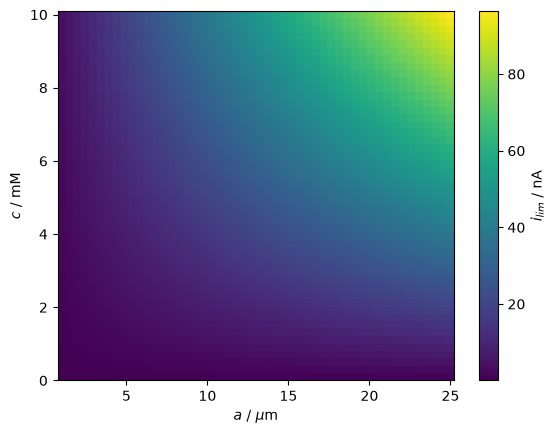

In [5]:
fig, ax = plt.subplots()
mesh = ax.pcolormesh(a*1e6, c, Z.T*1e9)
ax.set_xlabel(r"$a$ / $\mu$m")
ax.set_ylabel("$c$ / mM")
fig.colorbar(mesh, ax=ax, label=r"$i_{lim}$ / nA")
plt.show()

# Linear regression

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

In [7]:
X = grid
y = Z.ravel()

In [8]:
model = make_pipeline(
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    StandardScaler(),
    LinearRegression(),
)
model.fit(X, y)
print("Score:", model.score(X, y))

Score: 1.0


In [9]:
Z_pred = model.predict(X).reshape(len(a), len(c))

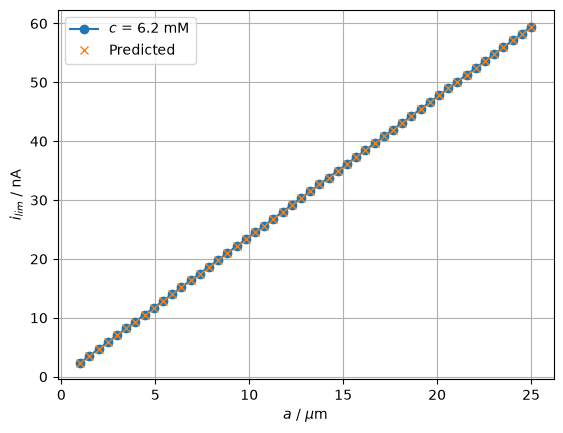

In [10]:
n = 30
fig, ax = plt.subplots()
ax.plot(a*1e6, Z[:,n]*1e9, "o-", label=fr"$c$ = {c[n]:.1f} mM")
ax.plot(a*1e6, Z_pred[:,n]*1e9, "x", label="Predicted")
ax.set_xlabel(r"$a$ / $\mu$m")
ax.set_ylabel(r"$i_{lim}$ / nA")
plt.grid()
plt.legend()
plt.show()

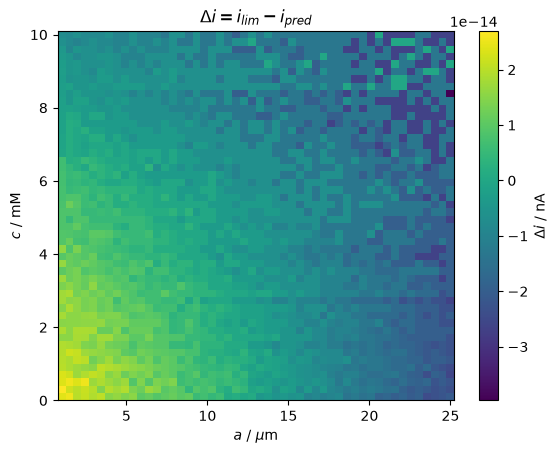

In [11]:
fig, ax = plt.subplots()
mesh = ax.pcolormesh(a*1e6, c, (Z.T-Z_pred.T)*1e9)
ax.set_xlabel(r"$a$ / $\mu$m")
ax.set_ylabel("$c$ / mM")
ax.set_title(r"$\Delta i = i_{lim} - i_{pred}$")
fig.colorbar(mesh, ax=ax, label=r"$\Delta i$ / nA")
plt.show()